In [1]:
# Import required standard and custom libraries
from datetime import datetime, timedelta
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2, chi2_contingency

In [2]:
# Some EDA questions of interest:
# -- What is the proportion of phone models by brand overall?
# -- What is the proportion of phone models that have end of security update dates versus those that do not?
# -- What is the proportion of phone models that have minimum security support end dates versus those that do not?
# -- Which phone models have already reached their date for the end of security updates?
# -- Which phone models have already reached their date for the end of minimum security support?
# -- What are the proportions of brands having phone models that have already reached their end date for security updates or minimum security support?
# -- What are some summary statistics, such as max, min, mean, and mode for each of the end dates?
# -- Are there particular regions that may be more impacted by having phone models that have reached their date for the end of security updates?
# -- Are there any phones released within the past four years that have already reached their date for the end of security updates?

In [3]:
# Read in the dataset into a Pandas dataframe
df = pd.read_csv("smartphone-update-support.csv")

In [4]:
# Print a basic summary of the dataset
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 712 entries, 0 to 711
Data columns (total 28 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   slug                            712 non-null    str    
 1   brand                           712 non-null    str    
 2   device_name                     712 non-null    str    
 3   model_identifier                132 non-null    str    
 4   region_scope                    712 non-null    str    
 5   release_date                    93 non-null     str    
 6   security_update_end             371 non-null    str    
 7   security_update_end_precision   371 non-null    str    
 8   security_update_end_basis       371 non-null    str    
 9   minimum_security_support_until  72 non-null     str    
 10  minimum_support_precision       72 non-null     str    
 11  minimum_support_model           72 non-null     str    
 12  minimum_support_region          72 non-null    

In [5]:
# Convert two variables of interest, security_update_end and minimum_security_support_until, to datetime. This will make them easier to use in comparison operations later.
df["security_update_end"] = pd.to_datetime(df["security_update_end"])
df["minimum_security_support_until"] = pd.to_datetime(df["minimum_security_support_until"])

In [6]:
# Print a quick summary of columns and the number of null values they contain
print(df.isnull().sum())

slug                                0
brand                               0
device_name                         0
model_identifier                  580
region_scope                        0
release_date                      619
security_update_end               341
security_update_end_precision     341
security_update_end_basis         341
minimum_security_support_until    640
minimum_support_precision         640
minimum_support_model             640
minimum_support_region            640
os_upgrade_end                    688
os_upgrade_end_precision          688
os_support_commitment             332
os_upgrade_generations            674
update_cadence                    337
latest_known_version              553
evidence_level                      0
evidence_label                      0
derivation_note                     0
source_title                        0
source_publisher                    0
source_url                          0
source_checked_date                 0
additional_s

In [7]:
# Print some basic summary statistics for each column
print(df.describe(include='all'))

                slug brand device_name model_identifier  \
count            712   712         712              132   
unique           712    17         712              132   
top     apple-iphone  vivo      iPhone            A1203   
freq               1   142           1                1   
mean             NaN   NaN         NaN              NaN   
min              NaN   NaN         NaN              NaN   
25%              NaN   NaN         NaN              NaN   
50%              NaN   NaN         NaN              NaN   
75%              NaN   NaN         NaN              NaN   
max              NaN   NaN         NaN              NaN   
std              NaN   NaN         NaN              NaN   

                                             region_scope release_date  \
count                                                 712           93   
unique                                                 44           57   
top     vivo global security-update list (availability...   2023-09-2

In [8]:
# Print the first 5 rows of the dataset
print(df.head())

                      slug  brand        device_name model_identifier  \
0             apple-iphone  Apple             iPhone            A1203   
1          apple-iphone-11  Apple          iPhone 11            A2111   
2      apple-iphone-11-pro  Apple      iPhone 11 Pro            A2160   
3  apple-iphone-11-pro-max  Apple  iPhone 11 Pro Max            A2161   
4          apple-iphone-12  Apple          iPhone 12            A2172   

                                  region_scope release_date  \
0  Region not specified in Apple model listing          NaN   
1                        Canada, United States   2019-09-20   
2                        Canada, United States          NaN   
3                        Canada, United States          NaN   
4                                United States   2020-10-23   

  security_update_end security_update_end_precision security_update_end_basis  \
0                 NaT                           NaN                       NaN   
1                 Na

In [9]:
# Print the unique values for the brand column
unique_brands = df.brand.unique()
print(f"\nThere are {len(unique_brands)} brands total represented in the dataset. They are: {', '.join(unique_brands)}.\n")


There are 17 brands total represented in the dataset. They are: Apple, Fairphone, Google, HMD, HONOR, iQOO, Motorola, Nokia, Nothing, OnePlus, OPPO, POCO, realme, Redmi, Samsung, vivo, Xiaomi.



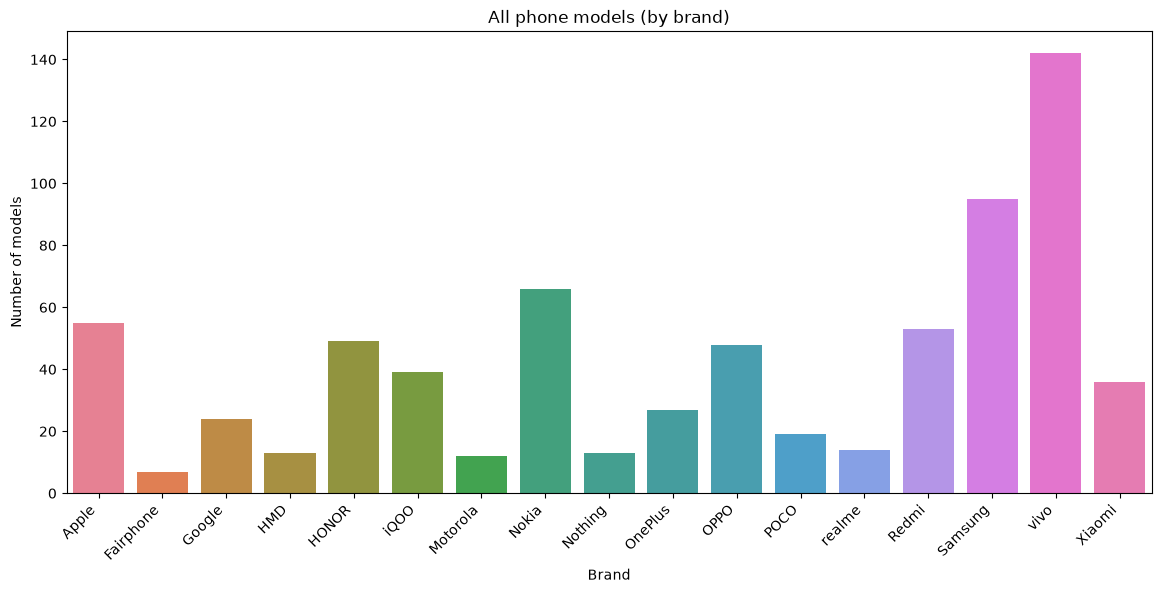

In [10]:
# Create a bar chart showing the total number of phone models by brand. We see that vivo has the most represented in the dataset, and Fairphone the fewest.
plt.figure(figsize=(14, 6))
sns.countplot(x="brand", data=df, hue="brand", legend=False)
plt.title("All phone models (by brand)")
plt.xlabel("Brand")
plt.ylabel("Number of models")
plt.xticks(rotation=45, ha="right")
plt.show()
plt.close()

In [11]:
# The security_update_end column is not null when a phone model has a manufacturer-stated or implied date. Print numbers for models with a known date and those without.
models_with_su_end_date = df[df.security_update_end.notnull()]
models_without_su_end_date = df[df.security_update_end.isnull()]
print(f"\nThere are {len(models_with_su_end_date)} phone models with a known end date for security updates, and {len(models_without_su_end_date)} phone models without a known date.\n")


There are 371 phone models with a known end date for security updates, and 341 phone models without a known date.



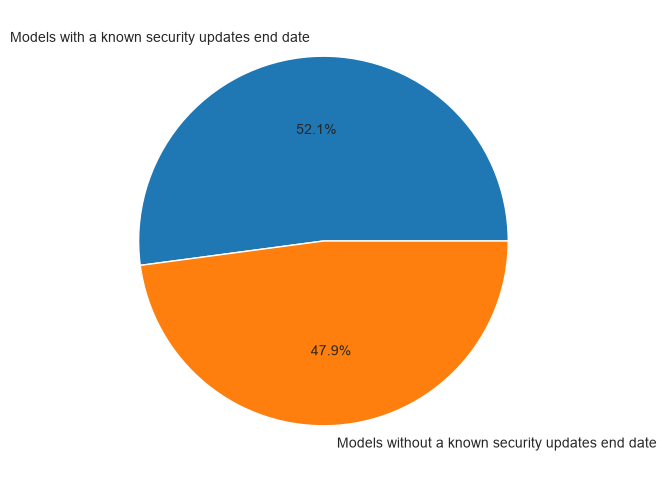

In [12]:
# Create a pie chart showing the proportion of phone models with a known end date for security updates and those without
data = {
    "labels": ["Models with a known security updates end date", "Models without a known security updates end date"],
    "values": [len(models_with_su_end_date), len(models_without_su_end_date)]
}
pie_df = pd.DataFrame(data)
sns.set_style("whitegrid")
plt.figure(figsize=(6, 6))
plt.pie(pie_df["values"], labels=pie_df["labels"], autopct="%1.1f%%")
plt.show()
plt.close()

In [13]:
# Similarly, compute and print the models that have a known or unknown minimum security support until date
models_with_min_sec_date = df[df.minimum_security_support_until.notnull()]
models_without_min_sec_date = df[df.minimum_security_support_until.isnull()]
print(f"\nThere are {len(models_with_min_sec_date)} phone models with a known end date for minimum security support, and {len(models_without_min_sec_date)} models without a known date.\n")


There are 72 phone models with a known end date for minimum security support, and 640 models without a known date.



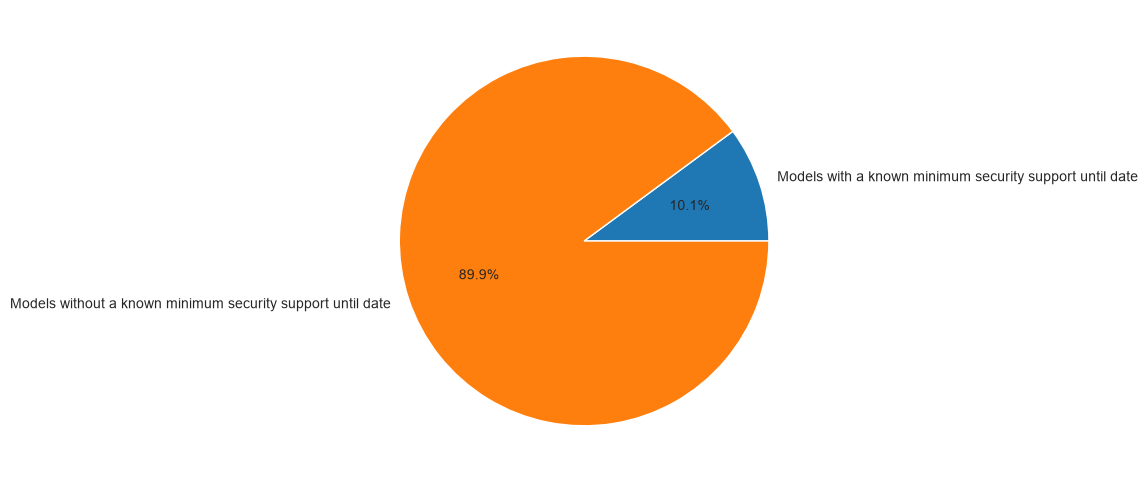

In [14]:
# Create a pie chart showing the proportion of phone models with a known end date for minimum security support and those without
data = {
    "labels": ["Models with a known minimum security support until date", "Models without a known minimum security support until date"],
    "values": [len(models_with_min_sec_date), len(models_without_min_sec_date)]
}
pie_df = pd.DataFrame(data)
sns.set_style("whitegrid")
plt.figure(figsize=(6, 6))
plt.pie(pie_df["values"], labels=pie_df["labels"], autopct="%1.1f%%")
plt.show()
plt.close()

In [15]:
# Compute phone models that have a security_update_end date that also have a minimum_security_support_until date
models_with_su_end_and_min_support = models_with_su_end_date[models_with_su_end_date.minimum_security_support_until.notnull()]
models_with_su_end_but_no_min_support = models_with_su_end_date[models_with_su_end_date.minimum_security_support_until.isnull()]
print(f"\nThere are {len(models_with_su_end_and_min_support)} phone models that have a known end date for security updates that also have a known end date for minimum security support, as compared to {len(models_with_su_end_but_no_min_support)} phone models without a known date for the end of minimum security support.\n")



There are 0 phone models that have a known end date for security updates that also have a known end date for minimum security support, as compared to 371 phone models without a known date for the end of minimum security support.



In [16]:
# Which phone models have already reached their end date for security updates?
models_reached_end_su_date = models_with_su_end_date[models_with_su_end_date.security_update_end <= datetime.now()]
print(f"\nThere are {len(models_reached_end_su_date)} phone models that have already reached their end date for security updates. They comprise {round(len(models_reached_end_su_date)/len(df) * 100, 2)}% of the dataset.\n")


There are 166 phone models that have already reached their end date for security updates. They comprise 23.31% of the dataset.



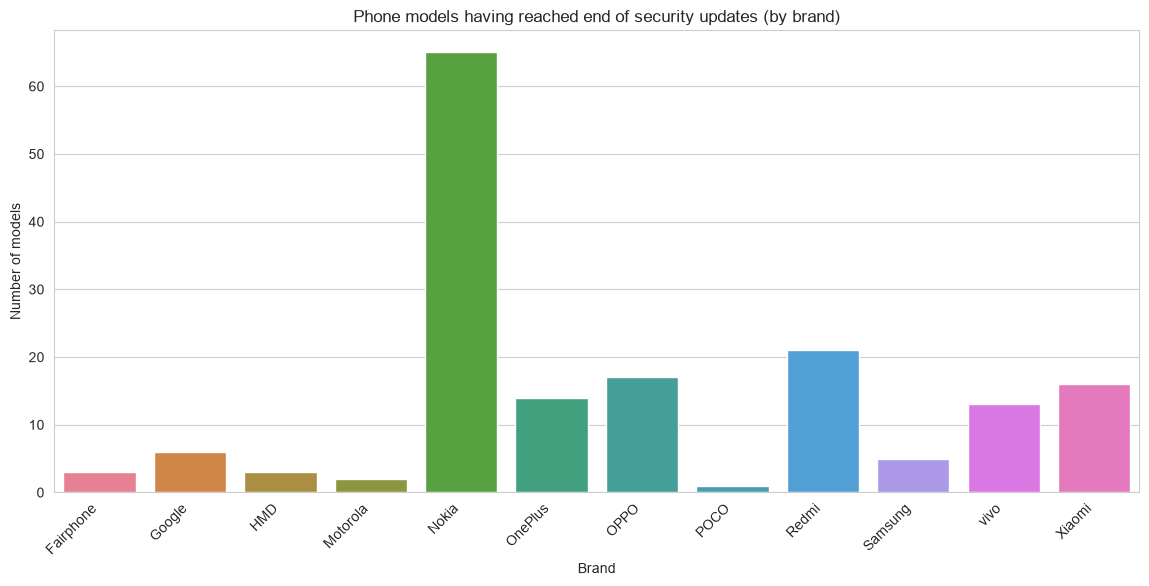

In [17]:
# Create a bar chart showing the phone models by brand that have reached their end date for security updates
plt.figure(figsize=(14, 6))
sns.countplot(x="brand", data=models_reached_end_su_date, hue="brand", legend=False)
plt.title("Phone models having reached end of security updates (by brand)")
plt.xlabel("Brand")
plt.ylabel("Number of models")
plt.xticks(rotation=45, ha="right")
plt.show()
plt.close()

In [18]:
# Compute and print the proportions for each brand represented in the bar chart above
print(models_reached_end_su_date.brand.value_counts(normalize=True))

brand
Nokia        0.391566
Redmi        0.126506
OPPO         0.102410
Xiaomi       0.096386
OnePlus      0.084337
vivo         0.078313
Google       0.036145
Samsung      0.030120
Fairphone    0.018072
HMD          0.018072
Motorola     0.012048
POCO         0.006024
Name: proportion, dtype: float64


In [19]:
# Which phones have already reached their end date for minimum security support?
models_reached_end_min_sec = models_with_min_sec_date[models_with_min_sec_date.minimum_security_support_until <= datetime.now()]
print(f"\nThere are {len(models_reached_end_min_sec)} phone models that have already reached their end date for minimum security updates. They comprise {round(len(models_reached_end_min_sec)/len(df),2)}% of the dataset.\n")


There are 12 phone models that have already reached their end date for minimum security updates. They comprise 0.02% of the dataset.



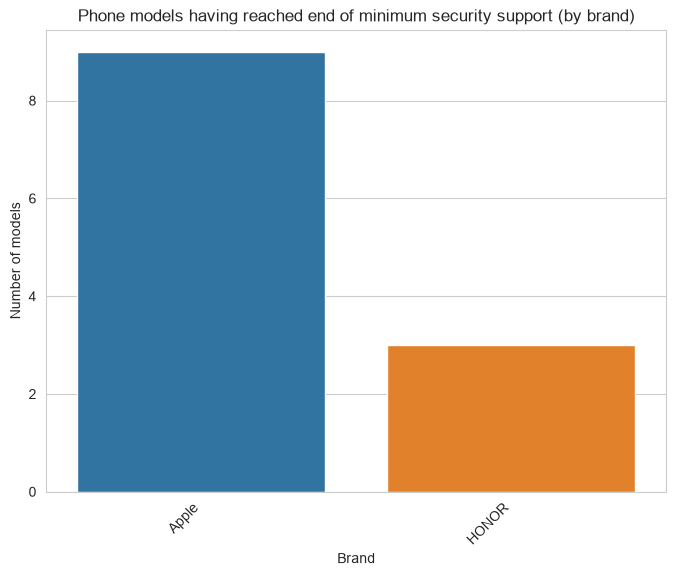

In [20]:
# Create a bar chart showing the phone models by brand that have reached their end date for minimum security support
plt.figure(figsize=(8, 6))
sns.countplot(x="brand", data=models_reached_end_min_sec, hue="brand", legend=False)
plt.title("Phone models having reached end of minimum security support (by brand)")
plt.xlabel("Brand")
plt.ylabel("Number of models")
plt.xticks(rotation=45, ha="right")
plt.show()
plt.close()

In [21]:
# Compute and print the proportions for each brand represented in the bar chart above
print(models_reached_end_min_sec.brand.value_counts(normalize=True))

brand
Apple    0.75
HONOR    0.25
Name: proportion, dtype: float64


In [22]:
# Compute and print the most common date for the end of security updates
most_common_sec_end_date = models_with_su_end_date.security_update_end.mode()[0]
print(f"\nThe most common end date for security updates is {most_common_sec_end_date.strftime("%B %d, %Y")} with {len(models_with_su_end_date[models_with_su_end_date.security_update_end == most_common_sec_end_date])} models having this date.\n")

# Compute and print the most common date for the end of minimum security support
most_common_min_sec_support_end = models_with_min_sec_date.minimum_security_support_until.mode()[0]
print(f"\nThe most common end date for minimum security support is {most_common_min_sec_support_end.strftime("%B %d, %Y")} with {len(models_with_min_sec_date[models_with_min_sec_date.minimum_security_support_until == most_common_min_sec_support_end])} models having this date.\n")


The most common end date for security updates is March 01, 2025 with 7 models having this date.


The most common end date for minimum security support is September 24, 2026 with 4 models having this date.



In [23]:
# Compute and print the mean, max, and min security updates end dates
print(f"\nThe mean security updates end date is {df.security_update_end.mean().strftime("%B %d, %Y")}.\n")
print(f"\nThe maximum security updates end date is {df.security_update_end.max().strftime("%B %d, %Y")}.\n")
print(f"\nThe minimum security updates end date is {df.security_update_end.min().strftime("%B %d, %Y")}.\n")


The mean security updates end date is July 28, 2027.


The maximum security updates end date is August 01, 2033.


The minimum security updates end date is May 01, 2019.



In [24]:
# Compute and print the mean, max, and min minimum security support until dates
print(f"\nThe mean minimum security support until end date is {df.minimum_security_support_until.mean().strftime("%B %d, %Y")}.\n")
print(f"\nThe maximum minimum security support until date is {df.minimum_security_support_until.max().strftime("%B %d, %Y")}.\n")
print(f"\nThe minimum minimum security support until date is {df.minimum_security_support_until.min().strftime("%B %d, %Y")}.\n")


The mean minimum security support until end date is July 24, 2028.


The maximum minimum security support until date is November 30, 2032.


The minimum minimum security support until date is September 20, 2024.



In [25]:
# How many phones released in the past four years have already reached their end date for security updates? (This might surprise their owners and is useful information!)
models_reached_end_su_date["release_date"] = pd.to_datetime(models_reached_end_su_date["release_date"])
recent_phones = models_reached_end_su_date[models_reached_end_su_date.release_date >= (datetime.now() - timedelta(weeks=208))]
print(f"\nThere are {len(recent_phones)} phone models released in the past four years that have already reached their end date for security updates, and they are the {', '.join(recent_phones.device_name)}.")


There are 2 phone models released in the past four years that have already reached their end date for security updates, and they are the moto g power 5G (2023), moto g73 5G.


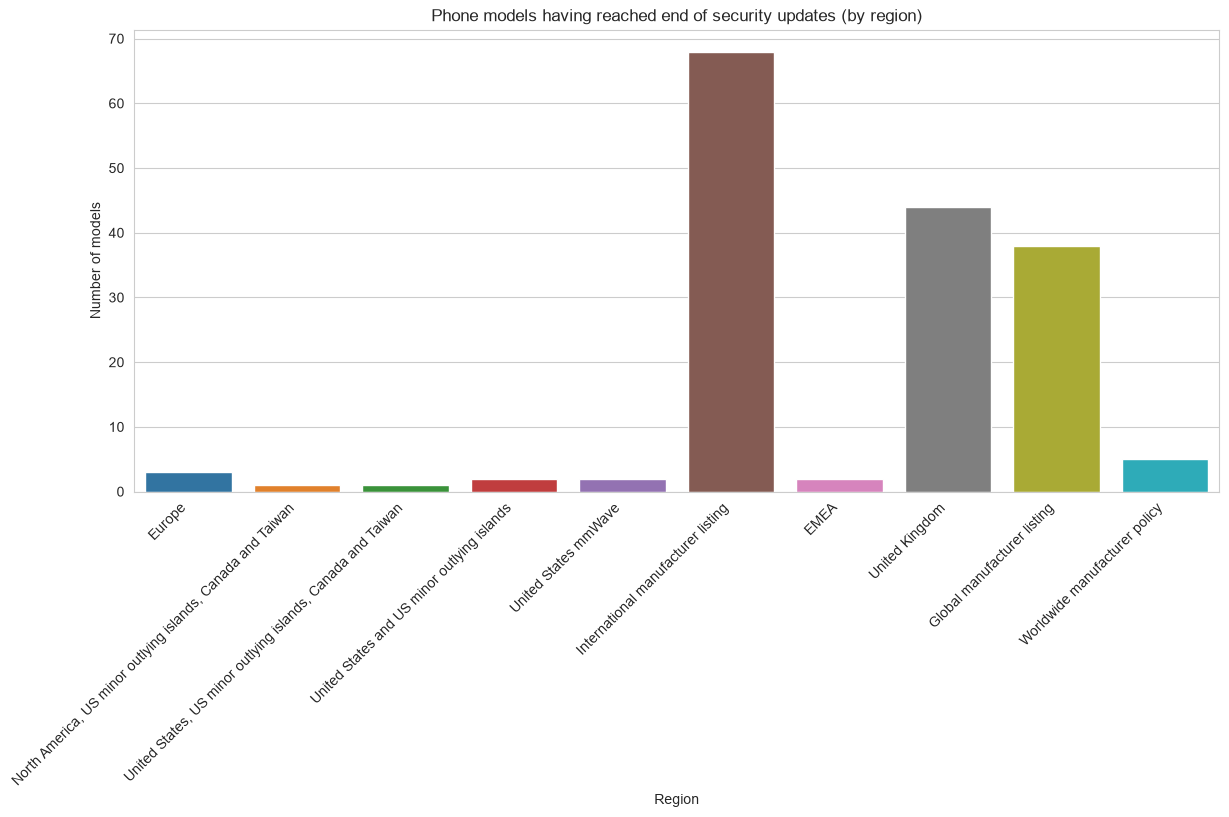

In [26]:
# Are there particular regions phone models are scoped to that are most impacted by models having already reached their end date?
plt.figure(figsize=(14, 6))
sns.countplot(x="region_scope", data=models_reached_end_su_date, hue="region_scope", legend=False)
plt.title("Phone models having reached end of security updates (by region)")
plt.xlabel("Region")
plt.ylabel("Number of models")
plt.xticks(rotation=45, ha="right")
plt.show()
plt.close()

In [27]:
# Create a new column which is of a boolean type and indicates if the model has a security updates end date or not. This will be used in the contingency table below.
df["has_security_updates_end_date"] = df.security_update_end.apply(lambda val: False if pd.isnull(val) else True)

In [33]:
# Create a contingency table of frequencies to investigate if there is an asssociation between the brand and has_security_update variables
brand_has_security_updates_end_date_freq = pd.crosstab(df.brand, df.has_security_updates_end_date)
print(f"The contingency table for brand and has_security_updates_end_date is as follows:\n\n{brand_has_security_updates_end_date_freq}\n.")

The contingency table for brand and has_security_updates_end_date is as follows:

has_security_updates_end_date  False  True 
brand                                      
Apple                             55      0
Fairphone                          0      7
Google                             0     24
HMD                                0     13
HONOR                             49      0
Motorola                           0     12
Nokia                              0     66
Nothing                           13      0
OPPO                               0     48
OnePlus                            0     27
POCO                               0     19
Redmi                              0     53
Samsung                           56     39
Xiaomi                             0     36
iQOO                              39      0
realme                             0     14
vivo                             129     13
.


In [29]:
# Convert the frequencies to proportions
table_proportions = brand_has_security_updates_end_date_freq / len(df)
print(f"The table of proportions for brand and has_security_update is as follows\n\n:{table_proportions}\n.")

The table of proportions for brand and has_security_update is as follows

:has_security_updates_end_date     False     True 
brand                                            
Apple                          0.077247  0.000000
Fairphone                      0.000000  0.009831
Google                         0.000000  0.033708
HMD                            0.000000  0.018258
HONOR                          0.068820  0.000000
Motorola                       0.000000  0.016854
Nokia                          0.000000  0.092697
Nothing                        0.018258  0.000000
OPPO                           0.000000  0.067416
OnePlus                        0.000000  0.037921
POCO                           0.000000  0.026685
Redmi                          0.000000  0.074438
Samsung                        0.078652  0.054775
Xiaomi                         0.000000  0.050562
iQOO                           0.054775  0.000000
realme                         0.000000  0.019663
vivo                     

In [30]:
# Compute and print the marginal proportions for the brand variable
brand_marginals = table_proportions.sum(axis=1)
print(f"The marginal proportions for the brand variable are as follows:\n\n{brand_marginals}.")

The marginal proportions for the brand variable are as follows:

brand
Apple        0.077247
Fairphone    0.009831
Google       0.033708
HMD          0.018258
HONOR        0.068820
Motorola     0.016854
Nokia        0.092697
Nothing      0.018258
OPPO         0.067416
OnePlus      0.037921
POCO         0.026685
Redmi        0.074438
Samsung      0.133427
Xiaomi       0.050562
iQOO         0.054775
realme       0.019663
vivo         0.199438
dtype: float64.


In [31]:
# Compute and print the marginal proportions for the has_security_update variable
has_security_updates_end_date_marginals = table_proportions.sum(axis=0)
print(f"The marginal proportions for the has_security_updates_end_date variable are as follows:\n\n{has_security_updates_end_date_marginals}.")

The marginal proportions for the has_security_updates_end_date variable are as follows:

has_security_updates_end_date
False    0.478933
True     0.521067
dtype: float64.


In [32]:
# The Chi-Square statistic and contingency table of expected frequencies demonstrate that brand and has_security_update_end appear to be highly associated
chi2_stat, p, dof, expected = chi2_contingency(brand_has_security_updates_end_date_freq)
# Compute the critical value at 0.01
critical_value = chi2.ppf(0.99, df=dof) # alpha = 0.01
print(f"\nThe Chi-Square statistic value is {round(chi2_stat, 2)}. For a 2x17 table, a value well above {round(critical_value, 3)} at an alpha=0.01 would suggest the variables are associated. Therefore, brand and has_security_updates_end_date have evidence of association.\n")
print(f"The contingency table of expected frequencies if the two variables were NOT associated is as follows:\n\n{np.round(expected)}.\n")


The Chi-Square statistic value is 572.56. For a 2x17 table, a value well above 32.0 at an alpha=0.01 would suggest the variables are associated. Therefore, brand and has_security_updates_end_date have evidence of association.

The contingency table of expected frequencies if the two variables were NOT associated is as follows:

[[26. 29.]
 [ 3.  4.]
 [11. 13.]
 [ 6.  7.]
 [23. 26.]
 [ 6.  6.]
 [32. 34.]
 [ 6.  7.]
 [23. 25.]
 [13. 14.]
 [ 9. 10.]
 [25. 28.]
 [45. 50.]
 [17. 19.]
 [19. 20.]
 [ 7.  7.]
 [68. 74.]].

